# Full-basket day states: 120 points in 182 dimensions

October 29, 2026. **The user's full-stock return-vector proposal is now executed.** This changes the measured object: each point is one day across the basket, rather than one stock's trailing history or PCA loadings.

Four declared additions compare raw/residual clouds and current H1 summaries/diagram changes. **Later risk point errors improve modestly; no incremental improvement is established. Mean-return prediction and the associated trading gates do not improve convincingly.** Every declared simultaneous interval spans zero.

[Full intuitive findings](experiments/equity_full_basket_states/README.md) · [specification](experiments/equity_full_basket_states/specification.json) · [source](experiments/equity_full_basket_states.py) · [running log](EQUITY_RESEARCH_LOG.md).

The daily portfolio is fixed. Results are gross/pre-fee. These dates and the survivor basket were already examined; this is exploratory work, not a fresh holdout.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
cwd=Path.cwd()
candidates=[cwd,cwd/"TDA_Research",cwd/"Senior-Fall"/"TDA_Research",*cwd.parents]
project=next(p for p in candidates if (p/"START_HERE.md").is_file() and (p/"equity").is_dir())
out=project/"equity"/"experiments"/"equity_full_basket_states"
result=json.loads((out/"summary.json").read_text())
audit=json.loads((out/"independent_audit.json").read_text())
metrics=pd.read_csv(out/"forecast_metrics.csv")
comparisons=pd.read_csv(out/"paired_incremental_comparisons.csv")
performance=pd.read_csv(out/"gate_performance.csv")
geometry=pd.read_csv(out/"geometry_diagnostics.csv",parse_dates=["formation_date"])
predictions=pd.read_csv(out/"walk_forward_predictions.csv")
assert all(result["checks"].values()) and all(audit["checks"].values())
print("Each cloud:",result["point_count"],"day points x",result["reference_stocks"],"stock coordinates")
print("Feature anchors:",result["feature_anchors"],"| forecasts:",result["predictions"])
print("Forecast scores:",result["forecast_scores_by_period"])
print("Daily calendar:",result["calendar_days_by_period"])
print("Conventional controls:",len(result["configuration"]["ordinary_controls"]))

Each cloud: 120 day points x 182 stock coordinates
Feature anchors: 490 | forecasts: 379
Forecast scores: {'boundary': 4, 'development': 233, 'later': 138}
Daily calendar: {'development': 1183, 'later': 708}
Conventional controls: 33


## 1. What exactly is a point?

One row is a day: `(stock1_return, ..., stock182_return)`. The prior 120 rows form one cloud in 182-dimensional space. Two rows are close if the basket's combinations of returns were similar. Stock membership is the previous fixed 182-name reference cohort, formed using initially available history. No future-completeness selection, changing coordinates, filling, or additional data is used.

**Raw** uses all log returns, including market movement. Dividing each row by sqrt(182) expresses its Euclidean distance as an RMS difference across stocks. **Residual** fits SPY out of each stock, standardizes its residual history, and uses all 182 resulting coordinates. No PCA truncation is applied to either cloud.

The 120-day window is held fixed. Diagrams use median-normalized distances; raw scale is restored for amplitude features. A centered cloud of 120 observations has rank at most 119, even with 182 coordinate columns. That algebraic bound does not mean discarded PCs: all observed stock-return coordinates enter the distances.

Effective rank below is an eigenvalue-concentration measure, not a proven intrinsic dimension or number of economic factors. Pair-distance spread is nonzero; this did not literally collapse to every day being equally distant. H1 intervals are comparatively short, which alone neither validates them nor proves they are noise.

,points,coordinates,distance_cv,effective_rank,H1_count,H1_max_shape
object,,,,,,
raw,120.0,182.0,0.2541,11.0357,11.0,0.0429
residual,120.0,182.0,0.2070,24.9929,7.0,0.0248


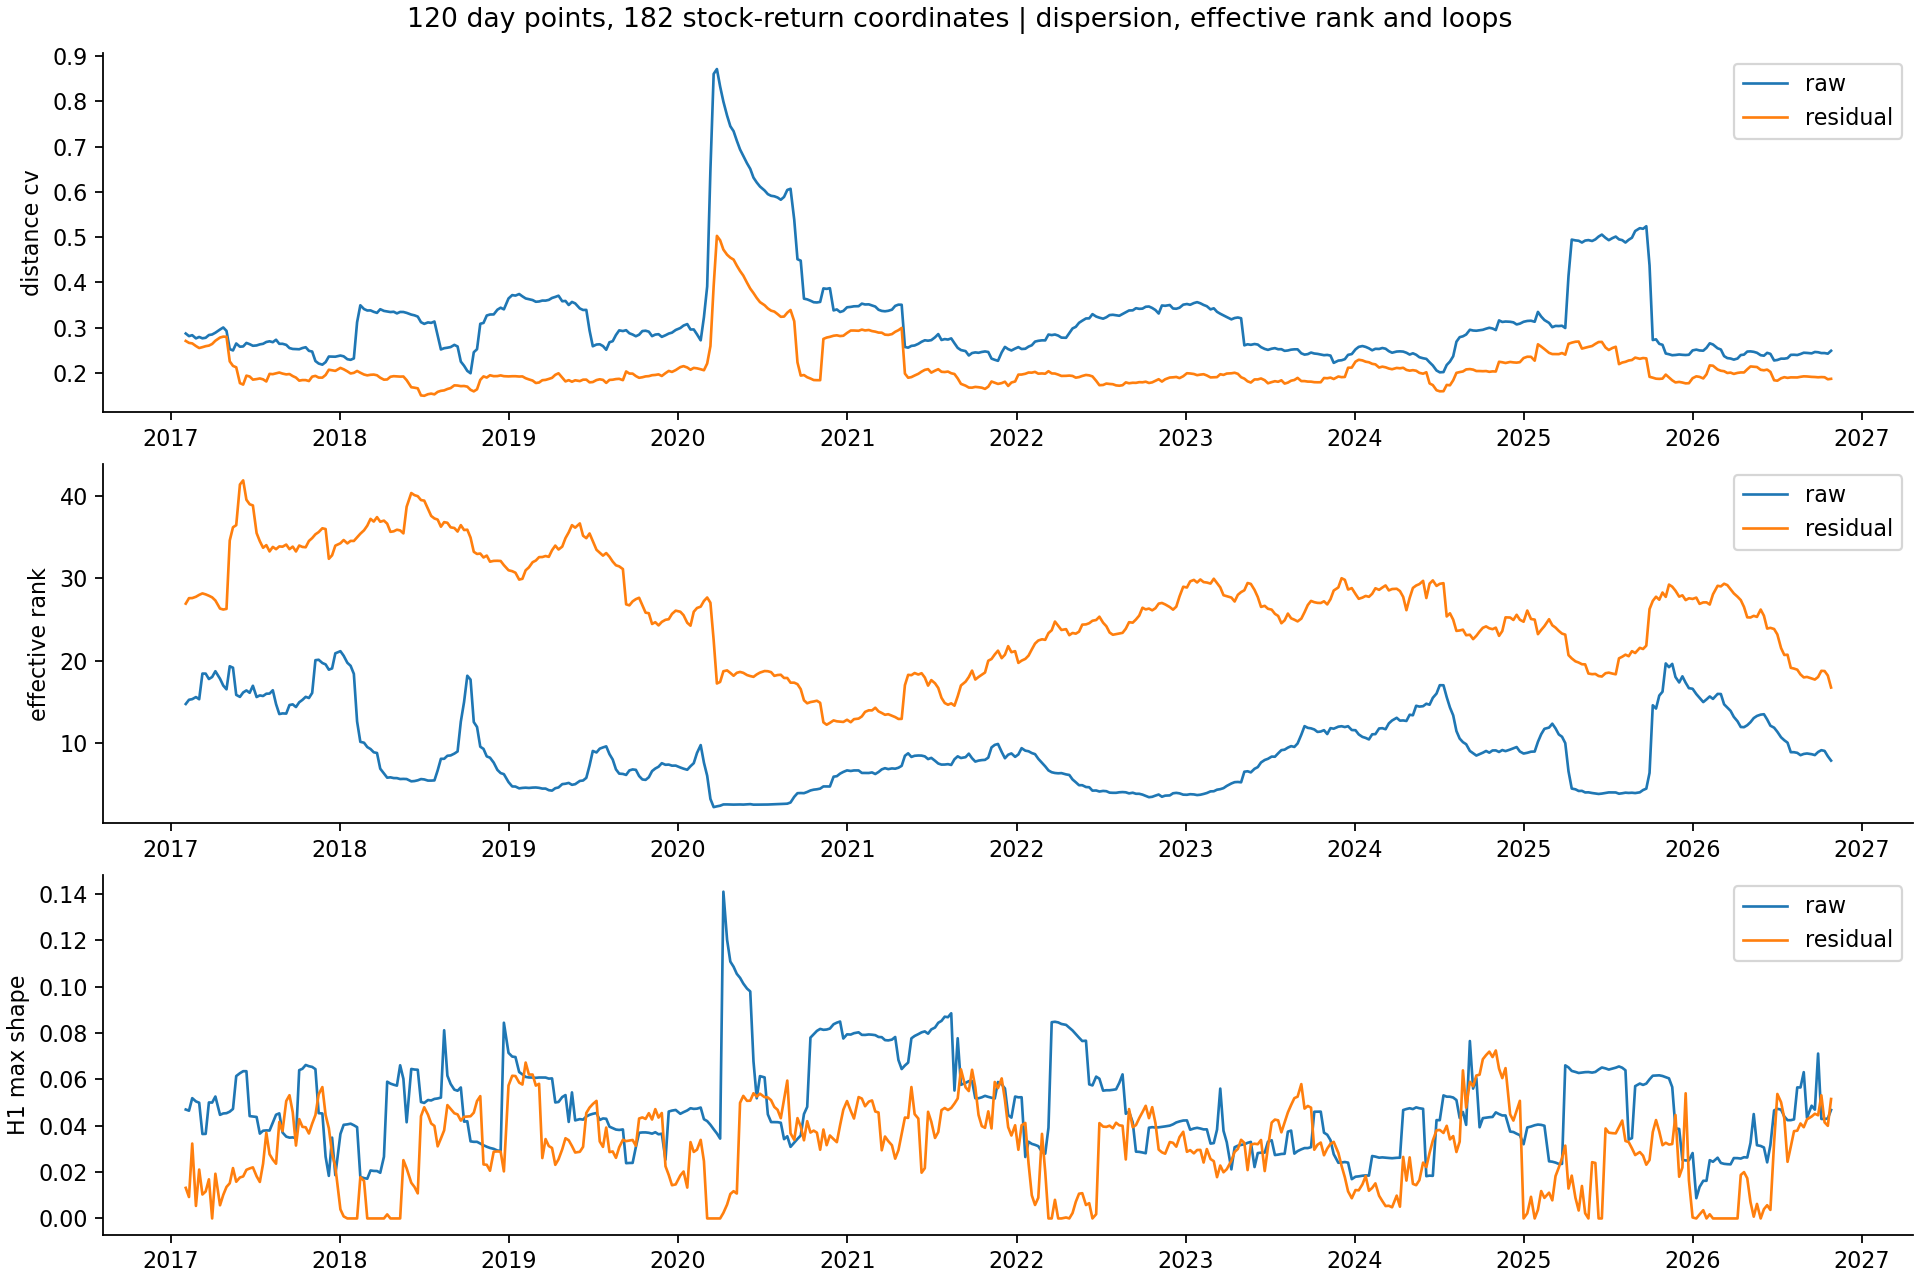

In [2]:
later=geometry.loc[geometry.formation_date.ge("2024-01-01")]
display(later.groupby("object")[["points","coordinates","distance_cv","effective_rank","H1_count","H1_max_shape"]].median().round(4))
display(Image(filename=str(out/"01_full_dimension_geometry.png")))

## 2. Current geometry versus changes in geometry

RawLevel adds H1 count, maximum raw lifetime, and raw squared-lifetime sum. ResidualLevel adds the corresponding normalized summaries. RawChange adds raw and normalized H1 diagram distances plus a signed change in squared lifetimes. ResidualChange adds normalized diagram distance and signed squared-lifetime change.

Diagram distance is the minimum cost of matching loop birth/death events between clouds, allowing loops to disappear or appear by matching to the diagonal. It does not match individual stocks or explain a regime's economic cause. The comparison is five sessions apart: **115 of the 120 days are shared**. Entering/leaving days or a scale change can drive it.

All additions share 33 conventional controls: the earlier state predictors, trailing strategy RMS, basket volatility, cloud scales/distance spread, MST connectivity, covariance concentration, and covariance/scale changes. H0 finite deaths equal MST edges and are included as ordinary controls. This asks whether H1 helps beyond cheap structural summaries, not whether extra predictors beat an empty model.

,object,transformation,normalized_H1_W1,scale_ratio
0,raw,day_permutation,0.0,1.0
1,raw,stock_permutation,0.0,1.0
2,raw,returns_times3,0.0,3.0
3,residual,day_permutation,0.0,1.0
4,residual,stock_permutation,0.0,1.0
5,residual,returns_times3,0.0,1.0


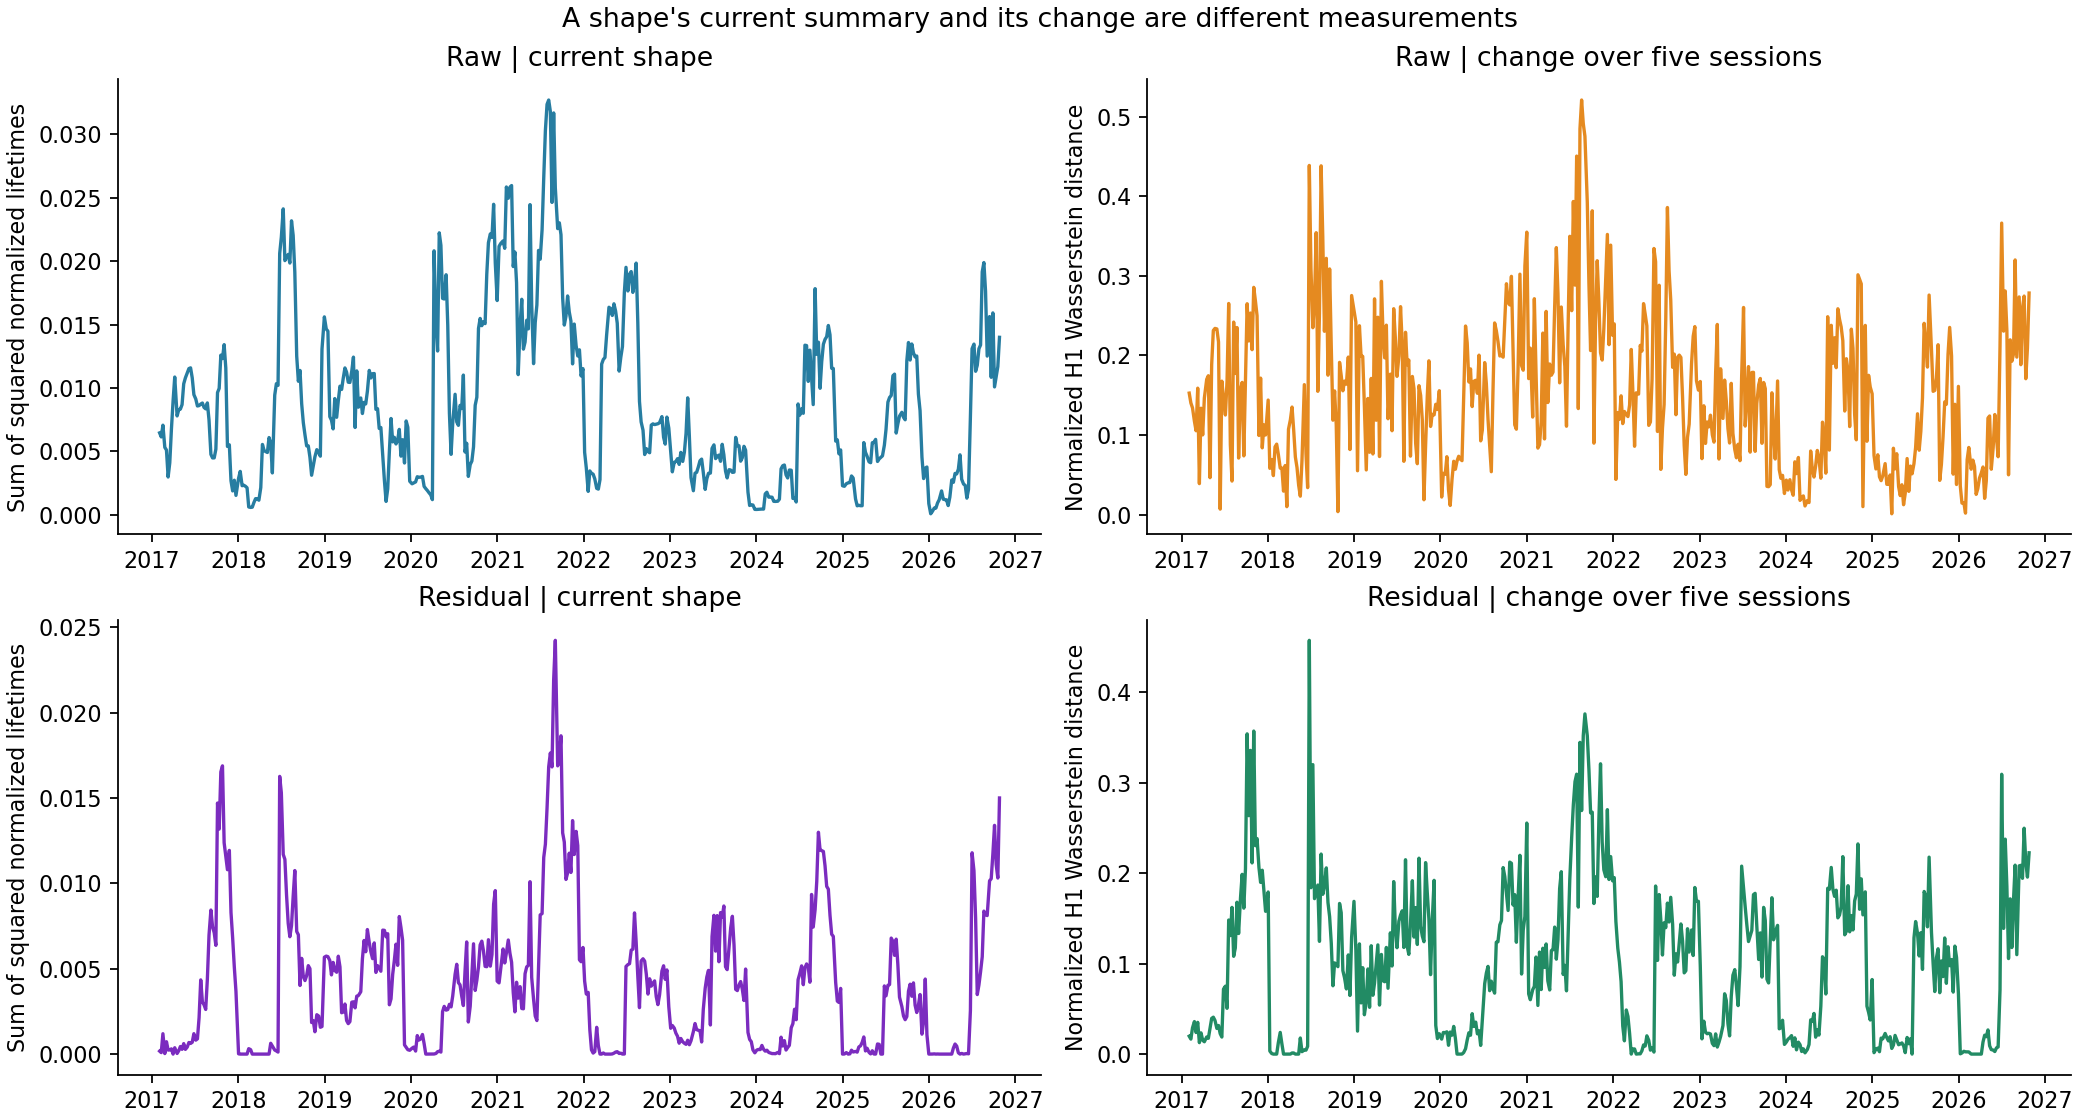

In [3]:
controls=pd.read_csv(out/"representation_controls.csv")
display(controls.round(7))
display(Image(filename=str(out/"04_levels_and_changes.png")))

## 3. Primary question: can it predict the amplitude of strategy returns?

The target is **log(next20-session RMS gross daily strategy return, in bps)**. RMS is square root of average squared returns: both large gains and large losses raise it. It is different from mean return, downside risk, or a discrete regime label. The primary error is squared log error; lower is better. A back-transformed prediction is a positive RMS estimate, not an asserted unbiased arithmetic conditional mean.

Both risk and mean models use exactly the original 379 forecast dates and completed training memberships. Training labels must have fully occurred; scalers use training data only. Ridge coefficient shrinkage stays fixed. At least 104 completed labels are needed, but the overlapping windows are not independent observations.

Later Controls log-RMS MSE is about **0.06924**. All four additions reduce its point error by **2.2–3.4%**. RawChange gives **0.06686**, paired difference **−0.00238**, simultaneous interval **[−0.00600,+0.00124]**. The evidence remains uncertain. Earlier changes are smaller and level additions slightly worsen point error. This is not a 3.4% reduction in realized trading risk.

,period,model,forecasts,MSE,RMS_MAE_bps,error_reduction_percent
0,development,HistoryMean,233,0.17153,7.19125,-26.74232
1,development,Controls,233,0.13534,6.82664,0.00000
2,development,RawLevel,233,0.13612,6.83478,-0.57991
3,development,RawChange,233,0.13475,6.83622,0.43266
4,development,ResidualLevel,233,0.13577,6.86486,-0.31613
5,development,ResidualChange,233,0.13496,6.83025,0.27773
12,later,HistoryMean,138,0.08412,5.34851,-21.48694
13,later,Controls,138,0.06924,4.84372,0.00000
14,later,RawLevel,138,0.06766,4.84028,2.27541
15,later,RawChange,138,0.06686,4.79197,3.43539


,period,model,difference,sim95_low,sim95_high
0,development,RawLevel,0.000785,-0.004441,0.006011
1,development,RawChange,-0.000586,-0.003908,0.002737
2,development,ResidualLevel,0.000428,-0.004144,0.005000
3,development,ResidualChange,-0.000376,-0.002874,0.002122
12,later,RawLevel,-0.001576,-0.007191,0.004040
13,later,RawChange,-0.002379,-0.006002,0.001245
14,later,ResidualLevel,-0.001524,-0.007148,0.004100
15,later,ResidualChange,-0.001544,-0.004009,0.000922


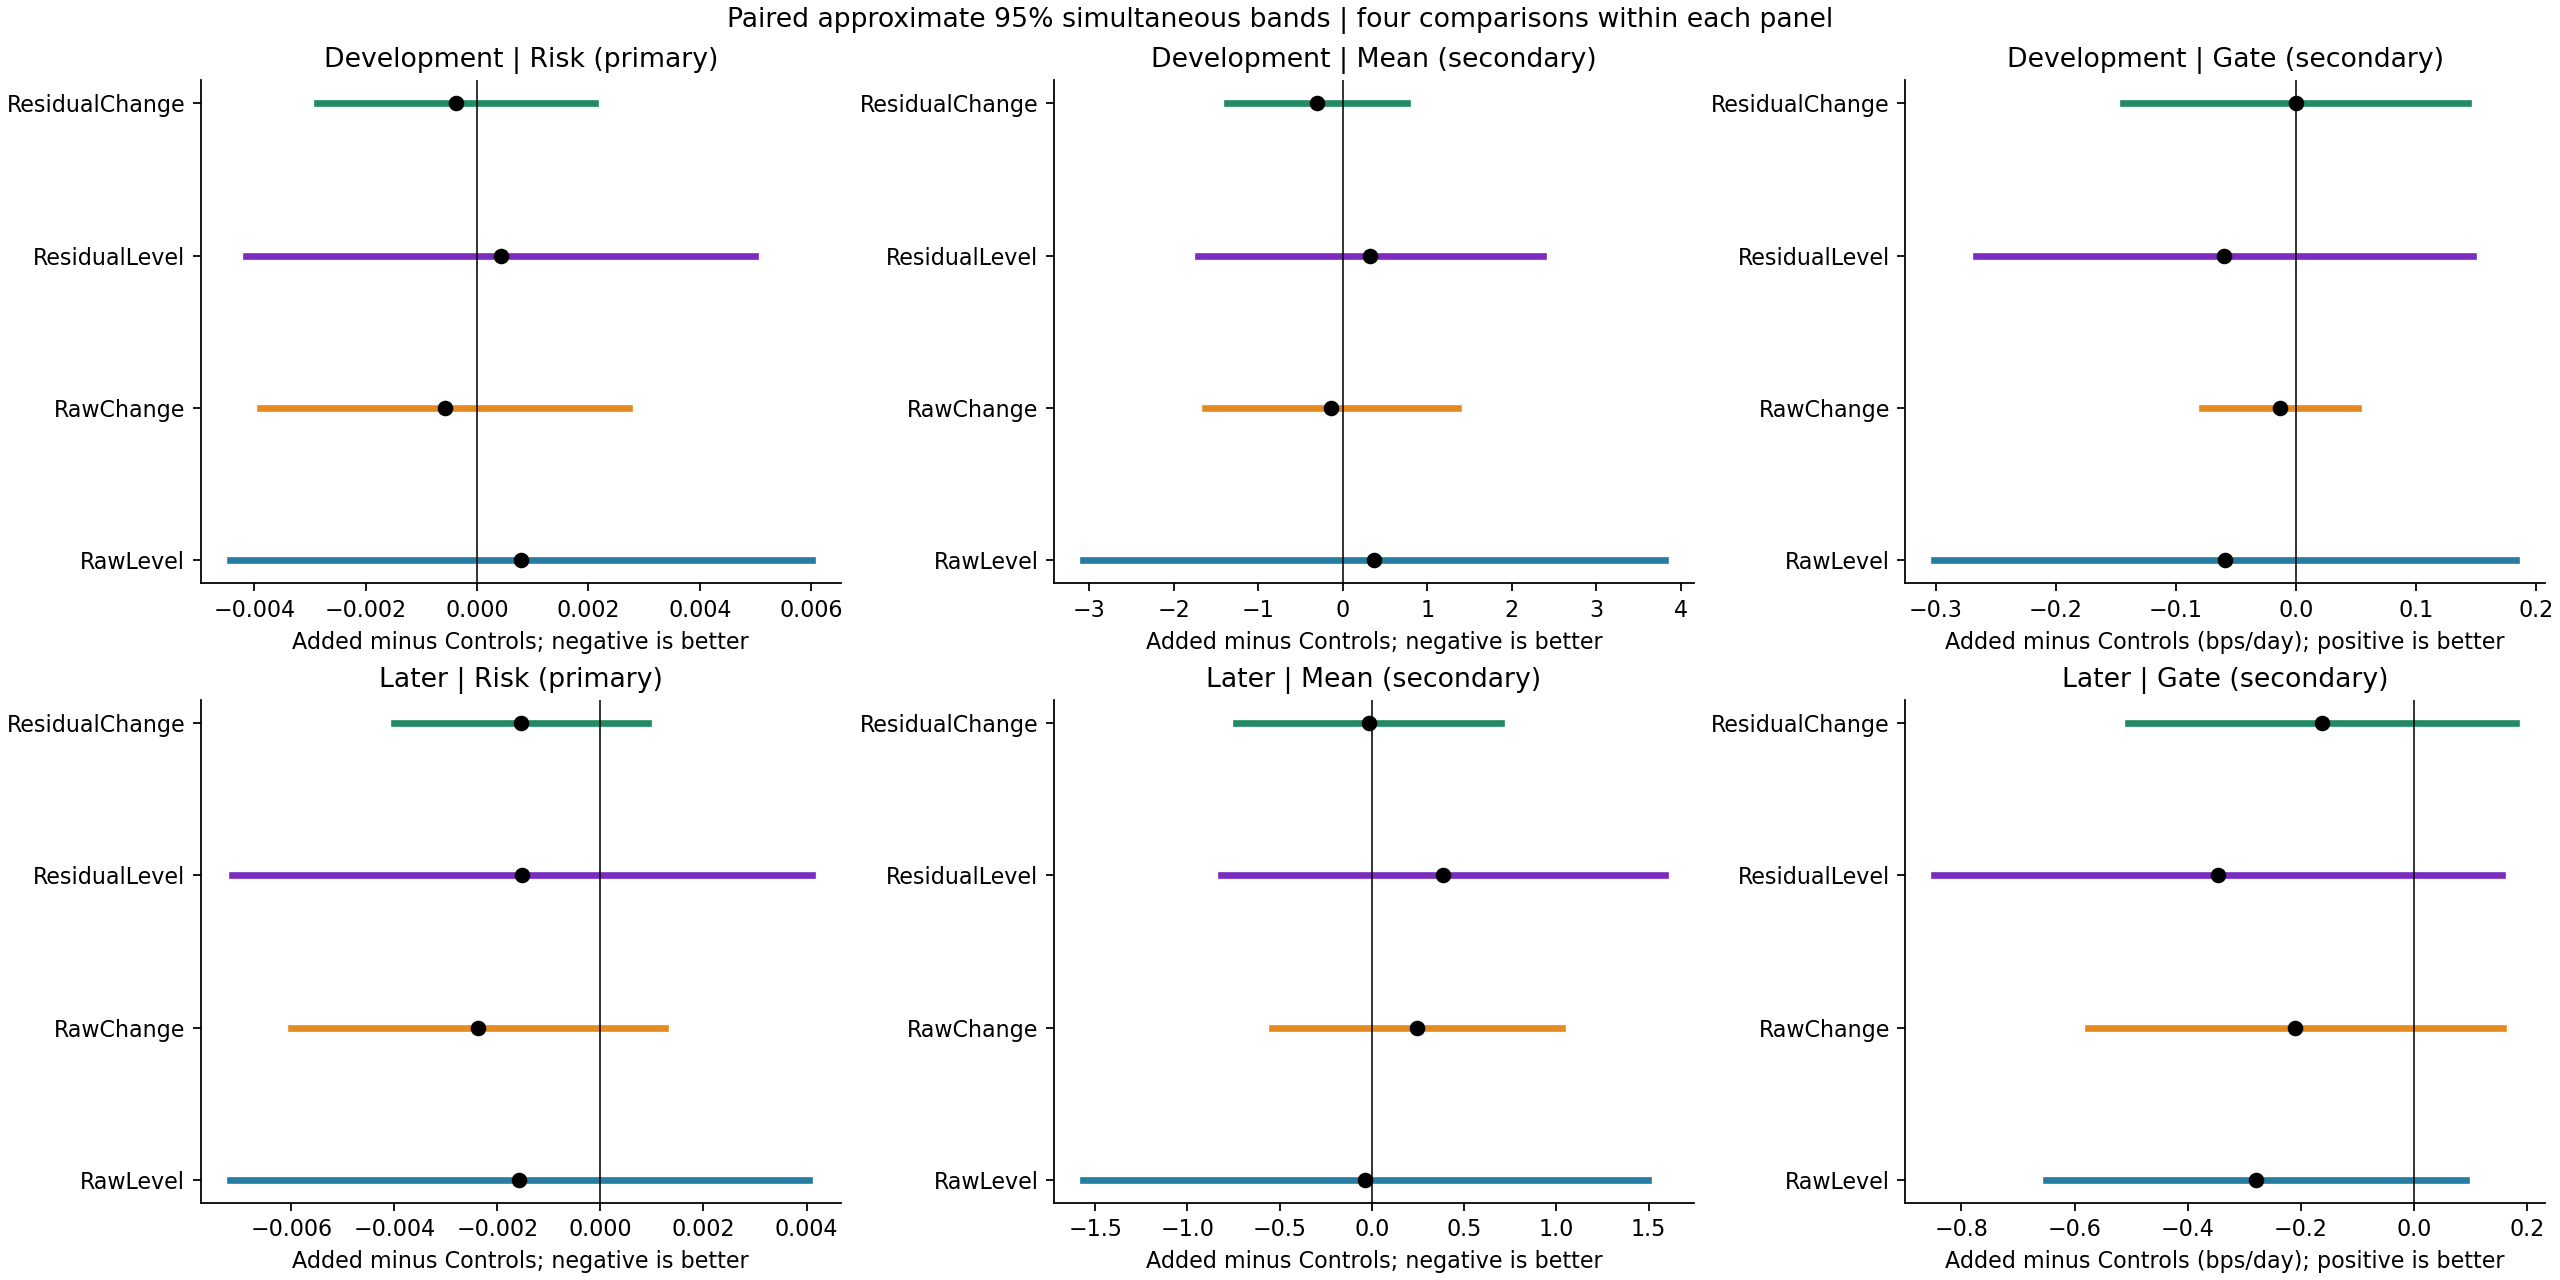

In [4]:
risk=metrics.loc[metrics.target.eq("risk")].copy()
risk["error_reduction_percent"]=risk.skill_vs_Controls*100
display(risk[["period","model","forecasts","MSE","RMS_MAE_bps","error_reduction_percent"]].round(5))
display(comparisons.loc[comparisons.metric.eq("logRMS_MSE"),["period","model","difference","sim95_low","sim95_high"]].round(6))
display(Image(filename=str(out/"02_incremental_comparisons.png")))

## 4. Secondary question: does it help forecast profitability or improve a gate?

The secondary target is the average of the next twenty daily strategy returns. A positive mean forecast activates the same original portfolio for the next five sessions; otherwise the stock portfolio is flat. We **do not gate on the risk forecast**, because high risk has not been shown to imply low expected reversal return.

The strategy still estimates factors/signals daily, buys relative underperformers and shorts outperformers with dollar/SPY/three-PC constraints, enters next daily-bar open, and exits that close. It does not hold today's stocks for twenty days. All flat zero-return days remain in the calendar. No costs of any kind are deducted.

Later mean forecast errors barely change. All four additions have worse later gate point means than Controls. Controls CAGR/Sharpe is **2.44%/0.79**; the additions range from **1.55–2.02% / 0.52–0.66**. Always-on remains **3.37%/0.89**. No daily mean or simultaneous incremental interval establishes an edge. Point rankings are not validated model selection. The older three-summary gate has a different baseline feature set and is preserved separately.

,period,model,MSE,MAE_native
6,development,HistoryMean,79.2784,5.9011
7,development,Controls,75.4421,5.7064
8,development,RawLevel,75.8118,5.7990
9,development,RawChange,75.3032,5.7369
10,development,ResidualLevel,75.7685,5.6938
11,development,ResidualChange,75.1361,5.6969
18,later,HistoryMean,32.2774,4.6935
19,later,Controls,35.1325,4.8909
20,later,RawLevel,35.0973,4.8882
21,later,RawChange,35.3761,4.9044


,period,model,mean_daily_bps,mean_low,mean_high,CAGR_percent,sharpe_vs_zero,active_percent
0,development,AlwaysOn,-0.197,-3.202,2.801,-0.590,-0.114,100.000
1,development,HistoryMean,-0.175,-1.516,0.919,-0.465,-0.194,38.462
2,development,Controls,0.769,-1.346,3.096,1.903,0.595,32.544
3,development,RawLevel,0.710,-1.402,2.993,1.752,0.548,33.812
4,development,RawChange,0.756,-1.369,3.097,1.870,0.584,32.967
5,development,ResidualLevel,0.710,-1.421,3.036,1.750,0.552,32.544
6,development,ResidualChange,0.769,-1.358,3.133,1.902,0.594,33.390
7,later,AlwaysOn,1.343,-0.584,3.409,3.367,0.890,100.000
8,later,HistoryMean,0.486,-1.305,2.384,1.169,0.348,83.475
9,later,Controls,0.977,-0.691,2.861,2.442,0.790,67.938


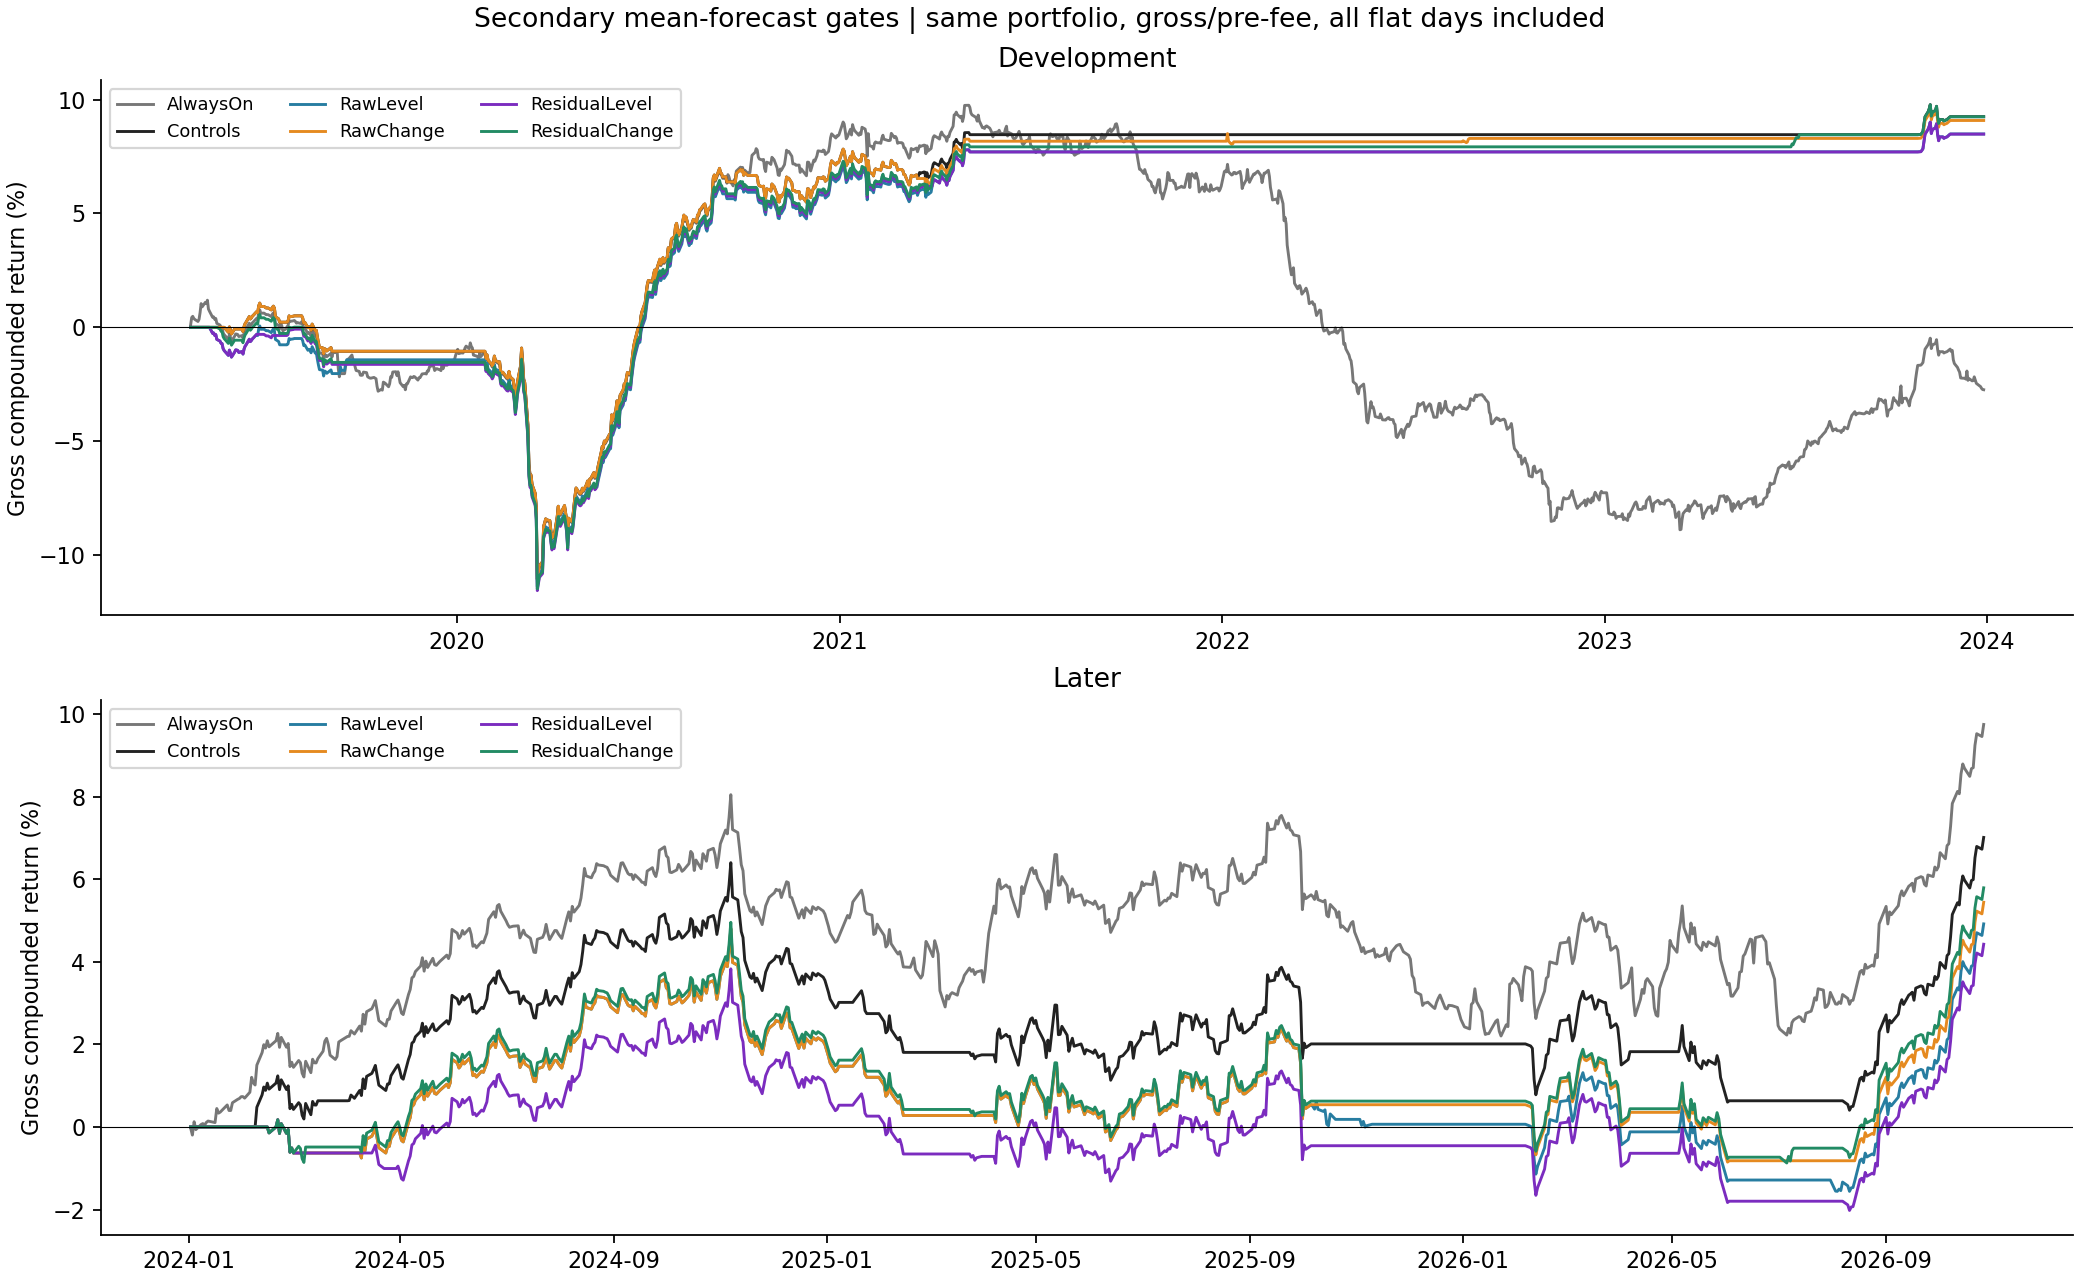

In [5]:
display(metrics.loc[metrics.target.eq("mean"),["period","model","MSE","MAE_native"]].round(4))
table=performance.copy()
table["CAGR_percent"]=table.gross_CAGR*100
table["active_percent"]=table.active_fraction*100
display(table[["period","model","mean_daily_bps","mean_low","mean_high","CAGR_percent","sharpe_vs_zero","active_percent"]].round(3))
display(Image(filename=str(out/"03_gross_gate_profit.png")))

## 5. What was learned, and what was not?

We completed a distinct test using the actual basket's full return vectors. It is not a reproduction of a four-index crash plot. The favorable later risk point estimates motivate keeping the representation as a benchmark, but they do not establish incremental value. There is no convincing improvement in expected-return prediction or this mean-forecast trading gate.

Day-order and stock-order permutations preserve each cloud. Uniform return scaling changes raw amplitude but not normalized geometry; standardized residuals remove that scale. Full nonzero-component PCA coordinates preserve every pair distance. These representation controls do not establish forecasting usefulness. We did not perform a matched stochastic-null test of the loops or learn a discrete set of economically interpreted regimes.

Four simultaneous augmentation comparisons are reported separately within each period/metric. Risk is primary; mean and trading are secondary. Blocks address some serial dependence, but uncertainty conditions on saved forecasts and does not correct across this project's historical experiments. The survivor universe, only about a decade of data, and already examined dates remain.

The audit independently reconstructs geometry, all diagram changes, both targets, and every fitted prediction/calendar statistic. The diagram matching is checked by a different match/delete/insert linear program. **Decision:** retain the fixed portfolio and this bounded result; do not choose RawChange or tune many dimensions/windows from its favorable point rank.

In [6]:
for name, passed in audit["checks"].items():
    print(name,passed)
print("State anchors checked:",audit["state_anchors_checked"])
print("Target/model/date fits reproduced:",audit["target_model_fits_checked"])
print("Maximum independent transport difference:",audit["max_transport_error"])
print("Maximum independent forecast difference:",audit["max_prediction_error"])
assert all(audit["checks"].values())

reference_membership_initial_past_only_and_complete True
every_full_dimension_distance_and_control_reconstructed True
all_H0_MST_pairs_match True
selected_H1_diagrams_independently_recomputed True
every_Wasserstein_distance_matches_independent_transport_LP True
every_risk_and_mean_label_matches_actual_daily_trades True
every_forecast_and_coefficient_matches_sklearn True
exact_completed_label_memberships_and_calendar True
all_gate_returns_and_reported_statistics_reproduced True
all_pointwise_and_simultaneous_intervals_reproduced True
protected_original_inputs_unchanged True
State anchors checked: 491
Target/model/date fits reproduced: 4548
Maximum independent transport difference: 1.070930011337623e-10
Maximum independent forecast difference: 2.007283228522283e-13
